In [1]:
# Data manipulation
import pandas as pd # for data manipulation

# Visualization
import plotly.express as px # for data visualization
import matplotlib.pyplot as plt # for showing handwritten digits

# Skleran
from sklearn.manifold import TSNE # for t-SNE dimensionality reduction

from dataset.dataset import load_data
from dataset.utils import *


import torch
import torch.nn as nn
import torchvision

from models.model import *

torch.set_printoptions(sci_mode=False)

from tqdm import tqdm

/home/jack/anaconda3/envs/playing_cards/lib/python3.10/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
N_CONCEPT = 17
N_CLASSES = 52
val_loader = load_data("./dataset/playing-cards/splits/single/val.pkl", 256, num_concepts=N_CONCEPT, dataset_root="./dataset/playing-cards/", return_orig=True, shuffle=True)

concept_index_to_string = IndexToString("./dataset/playing-cards/splits/single/concepts.txt")
class_index_to_string = IndexToString("./dataset/playing-cards/splits/single/classes.txt")

True image size (channels, width, height): torch.Size([3, 299, 299])
True  image concepts: tensor([1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0.])


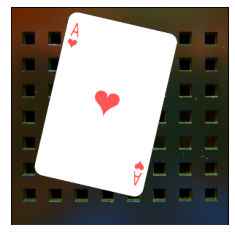

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


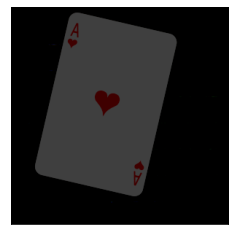

In [3]:
imageId = 7

images, labels, concepts, original_imgs = next(iter(val_loader))
image, label = images[imageId], labels[imageId]

# print / show input
print("True image size (channels, width, height):", image.size())
print("True  image concepts:", concepts[imageId])

plt.xticks([])
plt.yticks([])
plt.imshow(original_imgs[imageId].squeeze().permute(1, 2, 0))
plt.show()

plt.xticks([])
plt.yticks([])
plt.imshow(images[imageId].squeeze().permute(1, 2, 0))
plt.show()

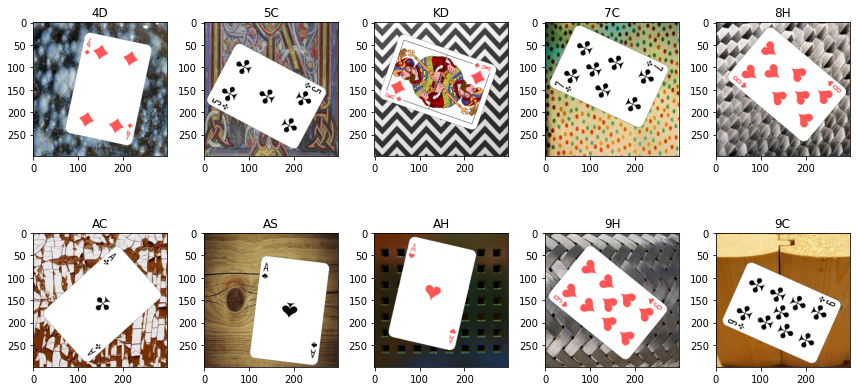

In [4]:
# Display images of the first 10 digits
fig, axs = plt.subplots(2, 5, sharey=False, tight_layout=True, figsize=(12,6), facecolor='white')
n=0
plt.gray() 
for i in range(0,2):
    for j in range(0,5):
        axs[i,j].imshow(original_imgs[n].squeeze().permute(1, 2, 0))
        axs[i,j].set(title=class_index_to_string(labels[n].item()))
        n=n+1
plt.show() 

In [5]:
print(images.view(images.size(0), -1).size())

print(labels.tolist())

torch.Size([512, 268203])
[13, 16, 45, 24, 30, 36, 39, 38, 34, 32, 13, 32, 39, 34, 10, 42, 32, 50, 21, 33, 19, 10, 41, 3, 17, 47, 6, 0, 1, 34, 19, 40, 33, 28, 18, 24, 0, 36, 51, 4, 28, 30, 8, 0, 44, 41, 25, 14, 31, 10, 29, 9, 4, 34, 38, 12, 36, 37, 28, 27, 18, 37, 12, 16, 37, 21, 24, 39, 38, 35, 17, 44, 23, 27, 1, 32, 10, 41, 2, 47, 23, 5, 4, 25, 42, 42, 9, 40, 33, 29, 14, 8, 16, 1, 31, 34, 47, 28, 27, 50, 8, 30, 25, 6, 49, 16, 39, 43, 25, 3, 51, 14, 38, 9, 42, 33, 35, 49, 0, 36, 35, 1, 32, 25, 8, 12, 43, 8, 19, 44, 48, 48, 26, 23, 22, 48, 14, 30, 46, 4, 32, 21, 37, 24, 26, 16, 30, 33, 29, 43, 48, 14, 49, 20, 48, 29, 27, 27, 34, 45, 21, 14, 38, 9, 21, 43, 4, 6, 41, 1, 43, 49, 40, 50, 32, 25, 48, 33, 14, 1, 38, 20, 36, 12, 2, 22, 15, 2, 41, 49, 38, 50, 50, 36, 47, 22, 41, 6, 2, 20, 1, 42, 2, 9, 51, 27, 33, 6, 41, 2, 6, 26, 23, 50, 29, 42, 21, 7, 9, 7, 10, 36, 25, 33, 45, 10, 2, 13, 18, 8, 7, 46, 21, 13, 17, 12, 49, 35, 21, 4, 5, 42, 45, 15, 40, 4, 6, 42, 24, 37, 9, 1, 49, 20, 26, 49, 40

In [9]:
# Configure t-SNE function. 
embed = TSNE(
    n_components=3, # default=2, Dimension of the embedded space.
    perplexity=10, # default=30.0, The perplexity is related to the number of nearest neighbors that is used in other manifold learning algorithms.
    early_exaggeration=12, # default=12.0, Controls how tight natural clusters in the original space are in the embedded space and how much space will be between them. 
    learning_rate=200, # default=200.0, The learning rate for t-SNE is usually in the range [10.0, 1000.0]. If the learning rate is too high, the data may look like a ‘ball’ with any point approximately equidistant from its nearest neighbours. If the learning rate is too low, most points may look compressed in a dense cloud with few outliers.
    n_iter=5000, # default=1000, Maximum number of iterations for the optimization. Should be at least 250.
    n_iter_without_progress=300, # default=300, Maximum number of iterations without progress before we abort the optimization, used after 250 initial iterations with early exaggeration. 
    min_grad_norm=0.0000001, # default=1e-7, If the gradient norm is below this threshold, the optimization will be stopped.
    metric='euclidean', # default=’euclidean’, The metric to use when calculating distance between instances in a feature array.
    init='random', # {‘random’, ‘pca’} or ndarray of shape (n_samples, n_components), default=’random’. Initialization of embedding
    verbose=0, # default=0, Verbosity level.
    random_state=42, # RandomState instance or None, default=None. Determines the random number generator. Pass an int for reproducible results across multiple function calls.
    method='barnes_hut', # default=’barnes_hut’. By default the gradient calculation algorithm uses Barnes-Hut approximation running in O(NlogN) time. method=’exact’ will run on the slower, but exact, algorithm in O(N^2) time. The exact algorithm should be used when nearest-neighbor errors need to be better than 3%. 
    angle=0.5, # default=0.5, Only used if method=’barnes_hut’ This is the trade-off between speed and accuracy for Barnes-Hut T-SNE.
    n_jobs=-1, # default=None, The number of parallel jobs to run for neighbors search. -1 means using all processors. 
)

# Transform X
X_embedded = embed.fit_transform(images.view(images.size(0), -1))

# Print results
print('New Shape of X: ', X_embedded.shape)
print('Kullback-Leibler divergence after optimization: ', embed.kl_divergence_)
print('No. of iterations: ', embed.n_iter_)
#print('Embedding vectors: ', embed.embedding_)

New Shape of X:  (512, 3)
Kullback-Leibler divergence after optimization:  1.7712212800979614
No. of iterations:  4999


In [2]:
# Create a scatter plot
fig = px.scatter_3d(None, x=X_embedded[:,0], y=X_embedded[:,1], z=X_embedded[:,2],
                 labels={
                     "x": "Dimension 1",
                     "y": "Dimension 2",
                     "z": "Dimension 3",
                 },
                 opacity=1, color=[str(x) for x in labels.tolist()])

# Change chart background color
fig.update_layout(dict(plot_bgcolor = 'white'))

# Update axes lines
fig.update_xaxes(showgrid=True, gridwidth=1, gridcolor='lightgrey', 
                 zeroline=True, zerolinewidth=1, zerolinecolor='lightgrey', 
                 showline=True, linewidth=1, linecolor='black')

fig.update_yaxes(showgrid=True, gridwidth=1, gridcolor='lightgrey', 
                 zeroline=True, zerolinewidth=1, zerolinecolor='lightgrey', 
                 showline=True, linewidth=1, linecolor='black')

# Set figure title
fig.update_layout(title_text="t-SNE")

# Update marker size
fig.update_traces(marker=dict(size=3))

fig.show()

NameError: name 'X_embedded' is not defined

# Predicted concept vector to task output

In [2]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
device = "cpu"
if torch.cuda.is_available():
    print("Device:", device, torch.cuda.get_device_name(0))
else:
    print("Device:", device)

Device: cpu NVIDIA GeForce GTX 1650 Ti


In [3]:
N_CONCEPT = 17
N_CLASSES = 52
val_loader = load_data("./dataset/playing-cards/splits/single/val.pkl", 16, num_concepts=N_CONCEPT, dataset_root="./dataset/playing-cards/", return_orig=True, shuffle=True)

concept_index_to_string = IndexToString("./dataset/playing-cards/splits/single/concepts.txt")
class_index_to_string = IndexToString("./dataset/playing-cards/splits/single/classes.txt")

XtoC = PlayingCardNet(num_classes=N_CONCEPT)
XtoC.load_state_dict(torch.load("./saves/XtoC_single_converted.pth", map_location=torch.device('cpu')))
XtoC.to(device)
XtoC.eval()

PlayingCardNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (13): ReLU(inplace=True)
    (14): M

In [4]:
features_labels = []

with torch.set_grad_enabled(False):
    for images, labels, concepts, original_imgs in tqdm(val_loader, unit="batch"):
        images, labels, concepts = images.to(device), labels.to(device), concepts.to(device)

        outputs = XtoC(images)

        concept_out = outputs

        features_labels.append((concept_out, labels))

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 189/189 [05:28<00:00,  1.74s/batch]


In [5]:
features = features_labels[0][0]
labels = features_labels[0][1]

for i in range(len(features_labels)-1):
    features = torch.cat((features, features_labels[i+1][0]), 0)
    labels = torch.cat((labels, features_labels[i+1][1]), 0)
    
print(features.size())
print(labels.size())

torch.Size([3016, 17])
torch.Size([3016])


In [6]:
# Configure t-SNE function. 
embed = TSNE(
    n_components=2, # default=2, Dimension of the embedded space.
    perplexity=10, # default=30.0, The perplexity is related to the number of nearest neighbors that is used in other manifold learning algorithms.
    early_exaggeration=12, # default=12.0, Controls how tight natural clusters in the original space are in the embedded space and how much space will be between them. 
    learning_rate=200, # default=200.0, The learning rate for t-SNE is usually in the range [10.0, 1000.0]. If the learning rate is too high, the data may look like a ‘ball’ with any point approximately equidistant from its nearest neighbours. If the learning rate is too low, most points may look compressed in a dense cloud with few outliers.
    n_iter=5000, # default=1000, Maximum number of iterations for the optimization. Should be at least 250.
    n_iter_without_progress=300, # default=300, Maximum number of iterations without progress before we abort the optimization, used after 250 initial iterations with early exaggeration. 
    min_grad_norm=0.0000001, # default=1e-7, If the gradient norm is below this threshold, the optimization will be stopped.
    metric='euclidean', # default=’euclidean’, The metric to use when calculating distance between instances in a feature array.
    init='random', # {‘random’, ‘pca’} or ndarray of shape (n_samples, n_components), default=’random’. Initialization of embedding
    verbose=0, # default=0, Verbosity level.
    random_state=42, # RandomState instance or None, default=None. Determines the random number generator. Pass an int for reproducible results across multiple function calls.
    method='barnes_hut', # default=’barnes_hut’. By default the gradient calculation algorithm uses Barnes-Hut approximation running in O(NlogN) time. method=’exact’ will run on the slower, but exact, algorithm in O(N^2) time. The exact algorithm should be used when nearest-neighbor errors need to be better than 3%. 
    angle=0.5, # default=0.5, Only used if method=’barnes_hut’ This is the trade-off between speed and accuracy for Barnes-Hut T-SNE.
    n_jobs=-1, # default=None, The number of parallel jobs to run for neighbors search. -1 means using all processors. 
)

# Transform X
X_embedded = embed.fit_transform(features.view(features.size(0), -1))

# Print results
print('New Shape of X: ', X_embedded.shape)
print('Kullback-Leibler divergence after optimization: ', embed.kl_divergence_)
print('No. of iterations: ', embed.n_iter_)
#print('Embedding vectors: ', embed.embedding_)

New Shape of X:  (3016, 2)
Kullback-Leibler divergence after optimization:  0.32693129777908325
No. of iterations:  4999


In [7]:
suit_colours = {
    "0": "#ff3333",
    "1": "#0066ff",
    "2": "#00ff00",
    "3": "#000000",
    "4": "#ff3333",
    "5": "#0066ff",
    "6": "#00ff00",
    "7": "#000000",
    "8": "#ff3333",
    "9": "#0066ff",
    "10": "#00ff00",
    "11": "#000000",
    "12": "#ff3333",
    "13": "#0066ff",
    "14": "#00ff00",
    "15": "#000000",
    "16": "#ff3333",
    "17": "#0066ff",
    "18": "#00ff00",
    "19": "#000000",
    "20": "#ff3333",
    "21": "#0066ff",
    "22": "#00ff00",
    "23": "#000000",
    "24": "#ff3333",
    "25": "#0066ff",
    "26": "#00ff00",
    "27": "#000000",
    "28": "#ff3333",
    "29": "#0066ff",
    "30": "#00ff00",
    "31": "#000000",
    "32": "#ff3333",
    "33": "#0066ff",
    "34": "#00ff00",
    "35": "#000000",
    "36": "#ff3333",
    "37": "#0066ff",
    "38": "#00ff00",
    "39": "#000000",
    "40": "#ff3333",
    "41": "#0066ff",
    "42": "#00ff00",
    "43": "#000000",
    "44": "#ff3333",
    "45": "#0066ff",
    "46": "#00ff00",
    "47": "#000000",
    "48": "#ff3333",
    "49": "#0066ff",
    "50": "#00ff00",
    "51": "#000000"
}

rank_colours = {
    "10C": "#ff6666",
    "10D": "#ff6666",
    "10H": "#ff6666",
    "10S": "#ff6666",
    "2C": "#ff8c66",
    "2D": "#ff8c66",
    "2H": "#ff8c66",
    "2S": "#ff8c66",
    "3C": "#ffd966",
    "3D": "#ffd966",
    "3H": "#ffd966",
    "3S": "#ffd966",
    "4C": "#d9ff66",
    "4D": "#d9ff66",
    "4H": "#d9ff66",
    "4S": "#d9ff66",
    "5C": "#8cff66",
    "5D": "#8cff66",
    "5H": "#8cff66",
    "5S": "#8cff66",
    "6C": "#66ffb3",
    "6D": "#66ffb3",
    "6H": "#66ffb3",
    "6S": "#66ffb3",
    "7C": "#66d9ff",
    "7D": "#66d9ff",
    "7H": "#66d9ff",
    "7S": "#66d9ff",
    "8C": "#668cff",
    "8D": "#668cff",
    "8H": "#668cff",
    "8S": "#668cff",
    "9C": "#8c66ff",
    "9D": "#8c66ff",
    "9H": "#8c66ff",
    "9S": "#8c66ff",
    "AC": "#d966ff",
    "AD": "#d966ff",
    "AH": "#d966ff",
    "AS": "#d966ff",
    "JC": "#ff668c",
    "JD": "#ff668c",
    "JH": "#ff668c",
    "JS": "#ff668c",
    "KC": "#000099",
    "KD": "#000099",
    "KH": "#000099",
    "KS": "#000099",
    "QC": "#000000",
    "QD": "#000000",
    "QH": "#000000",
    "QS": "#000000"
}

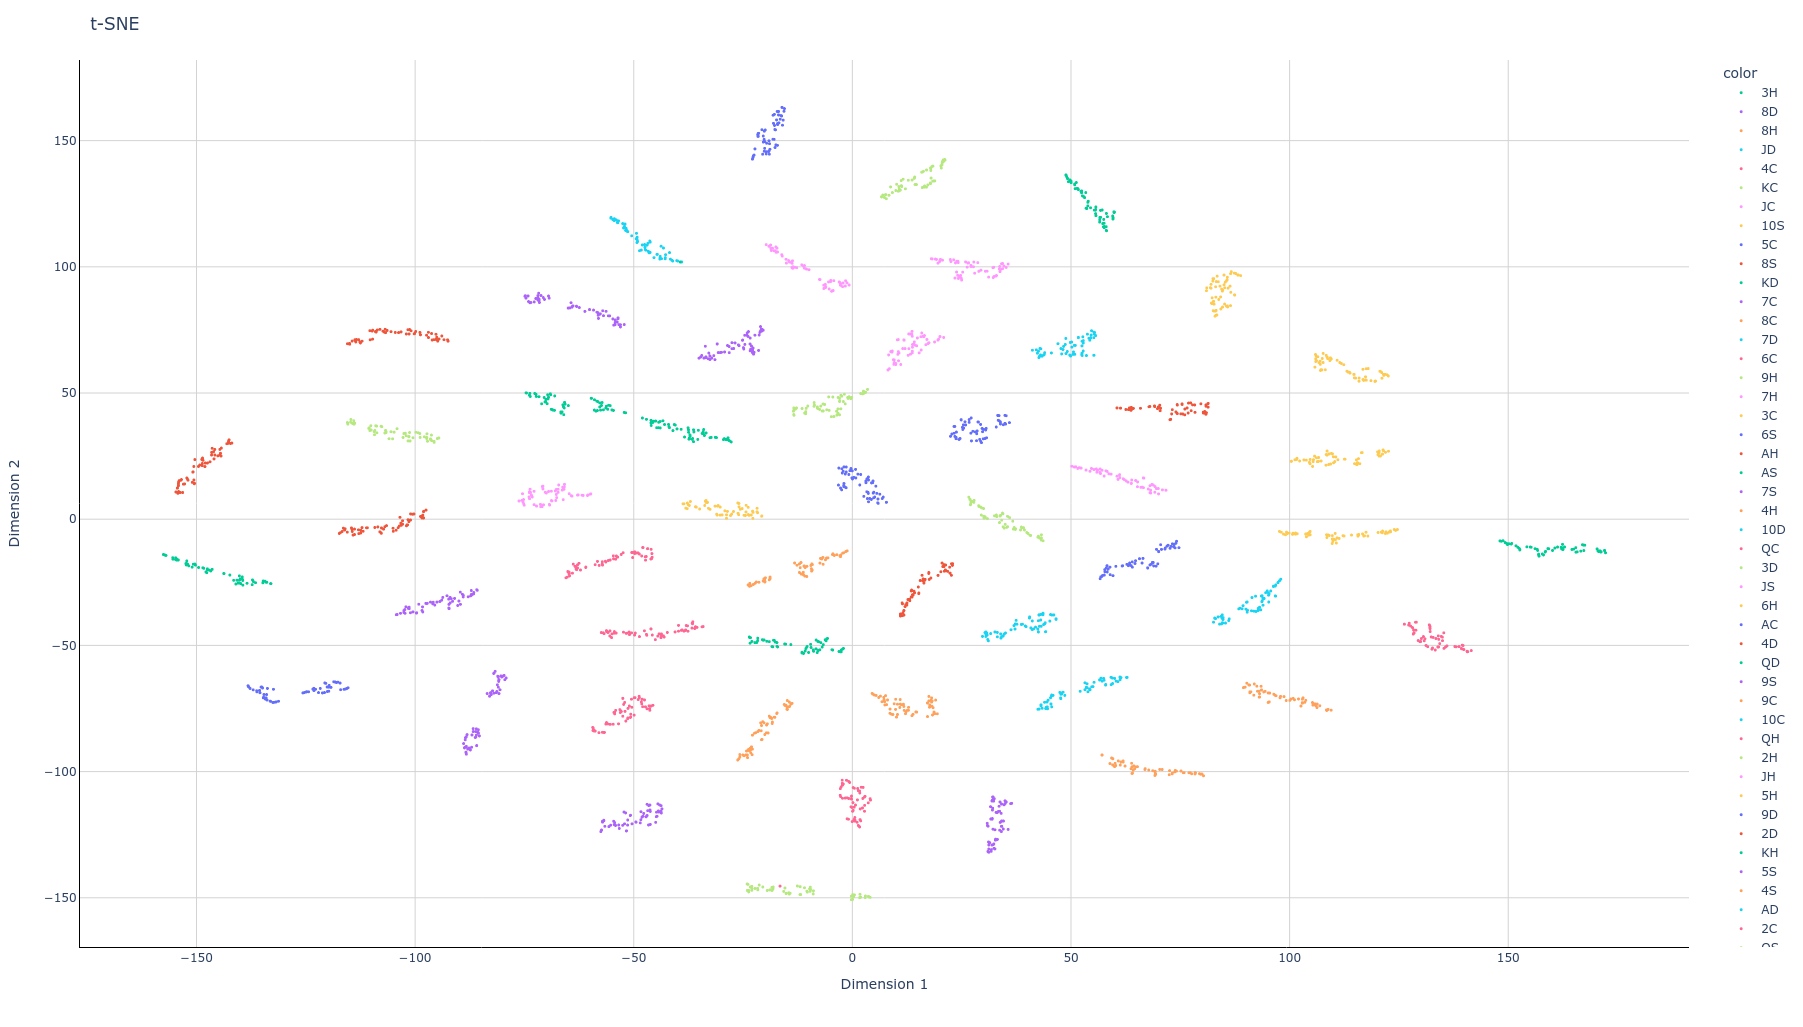

In [10]:
# Create a scatter plot
fig = px.scatter(None, x=X_embedded[:,0], y=X_embedded[:,1],
                 labels={
                     "x": "Dimension 1",
                     "y": "Dimension 2"
                 },
                 opacity=1, color=[class_index_to_string(x) for x in labels.tolist()], color_discrete_map=suit_colours)

"""
# Create a scatter plot
fig = px.scatter_3d(None, x=X_embedded[:,0], y=X_embedded[:,1], z=X_embedded[:,2],
                 labels={
                     "x": "Dimension 1",
                     "y": "Dimension 2",
                     "z": "Dimension 3",
                 },
                 opacity=1, color=[class_index_to_string(x) for x in labels.tolist()], color_discrete_map=rank_colours)
"""

# Change chart background color
fig.update_layout(dict(plot_bgcolor = 'white'))

# Update axes lines
fig.update_xaxes(showgrid=True, gridwidth=1, gridcolor='lightgrey', 
                 zeroline=True, zerolinewidth=1, zerolinecolor='lightgrey', 
                 showline=True, linewidth=1, linecolor='black')

fig.update_yaxes(showgrid=True, gridwidth=1, gridcolor='lightgrey', 
                 zeroline=True, zerolinewidth=1, zerolinecolor='lightgrey', 
                 showline=True, linewidth=1, linecolor='black')

# Set figure title
fig.update_layout(title_text="t-SNE")

# Update marker size
fig.update_traces(marker=dict(size=3))

fig.show()